# Do Kazakh LLMs Understand Latin-Script Kazakh?
### Evaluating LLM robustness to the Cyrillic → Latin script transition

**Author:** Tolkyn Zhagypar · **Last updated:** November 2026 · [GitHub repo](https://github.com/zhagypartolkyn/kazakh-latin-robustness)

Kazakhstan is gradually moving the Kazakh language from Cyrillic to Latin script, but current Kazakh-capable LLMs were trained mostly on Cyrillic text. This notebook measures how much model performance drops when the same Kazakh text is written in Latin script, and investigates why.

**Research questions**
1. How much accuracy do LLMs lose on Latin-script Kazakh compared to Cyrillic?
2. Does tokenizer fertility (tokens per word) increase for Latin script, and does it explain the drop?
3. What kinds of errors appear only in the Latin version?

**Setup**
- **Benchmark:** Belebele (Kazakh, 900 multiple-choice reading-comprehension questions), converted to Latin script with a rule-based transliterator following the 2021 official Kazakh Latin alphabet
- **Models:** Sherkala-8B (MBZUAI/Inception), KazLLM-8B (ISSAI), Llama-3.1-8B-Instruct, Qwen2.5-7B-Instruct, loaded in 4-bit
- **Method:** zero-shot, log-likelihood scoring over answer options A–D; paired comparison (Cyrillic vs. Latin) with a McNemar test

## How to use this notebook

**Every session: `Runtime → Run all`.** Each section checks what's already saved on Google Drive and skips work that's done, so re-running is safe. Nothing you've edited by hand is ever overwritten.

| Section | Needs GPU? | What you do |
|---|---|---|
| 0. Setup | no | nothing (approve the Google Drive popup) |
| 1. Config | no | **change `MODEL` before each evaluation session** |
| 2. Transliterator | no | nothing |
| 3. Benchmark | no | nothing (built once, then loaded from Drive) |
| 4. Gold sample | no | **once:** open `data/translit_gold_50.csv` in Google Sheets, correct the `gold_latin` column, save as CSV with the same name |
| 5. Tokenizer analysis | no | nothing |
| 6. Evaluation | **yes (T4)** | nothing, it runs the model set in `MODEL` |
| 7. Results table | no | nothing |
| 8. Error analysis | no | **once per model:** fill the `category` column in `results/errors_<model>.csv` |
| 9. Feature analysis | no | nothing |
| 10. И/Й merger | no | nothing |
| 11. Figures | no | nothing (saves the README figures to `results/figures/`) |

**Recommended workflow**
1. **First session (CPU runtime):** Run all. Sections 2–5 are built; section 6 skips itself because there's no GPU. Then edit the gold CSV.
2. **One session per model (T4 runtime):** set `MODEL` in section 1, Run all. Order: `sherkala` → `kazllm` → `qwen` → `llama`.
3. **Final session (CPU):** Run all to get the full results table, charts, and error analysis.

**Before starting:**
- Colab secret named `HF_TOKEN` added
- Hugging Face approved  access to the Llama-3.1, Sherkala and KazLLM model pages


## 0. Setup

In [1]:
!pip install -q -U transformers accelerate bitsandbytes datasets jiwer statsmodels

import os, csv, json, time, gc, random, re
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from huggingface_hub import login
from google.colab import drive, userdata

# Hugging Face login (falls back to a paste box if the secret is missing)
try:
    login(userdata.get("HF_TOKEN"))
except Exception as e:
    print("HF_TOKEN secret not available (", type(e).__name__, ") -> paste your token below")
    login()

drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/kazakh-latin-robustness"
DATA, OUT, TRANSLIT = f"{ROOT}/data", f"{ROOT}/results", f"{ROOT}/translit"
for d in (DATA, OUT, TRANSLIT):
    os.makedirs(d, exist_ok=True)

HAS_GPU = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (CPU runtime)")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Mounted at /content/drive
GPU: Tesla T4


## 1. Config
- Change `MODEL` before each evaluation session.
- Don't change `SUBSET_SIZE` after the first model has been evaluated, or the models won't be comparable.

In [2]:
MODEL = "kazllm"      # change before each GPU session: "sherkala", "kazllm", "qwen", "llama"

MODELS = {
    "sherkala": "inceptionai/Llama-3.1-Sherkala-8B-Chat",
    "kazllm":   "issai/LLama-3.1-KazLLM-1.0-8B",
    "qwen":     "Qwen/Qwen2.5-7B-Instruct",
    "llama":    "meta-llama/Llama-3.1-8B-Instruct",
}

# names used in tables and figures
MODEL_NAMES = {
    "sherkala": "Sherkala-Chat (8B)",
    "kazllm":   "KazLLM-1.0 (8B)",
    "qwen":     "Qwen2.5-7B-Instruct",
    "llama":    "Llama-3.1-8B-Instruct",
}

SUBSET_SIZE   = None    # None = all 900 questions; e.g. 400 if runs are too slow
SEED          = 42
BATCH_SIZE    = 8       # lowered automatically if the GPU runs out of memory
FORCE_REBUILD = False   # True only if the change in transliterator and want to rebuild the data

## 2. Transliterator (Cyrillic → Latin)
Based on the 2021 official Kazakh Latin alphabet.

In [3]:
TRANSLIT_CODE = r"""
# Kazakh Cyrillic -> Latin (2021 alphabet). Verify against the official source.
LOWER = {
    "а": "a", "ә": "ä", "б": "b", "в": "v", "г": "g", "ғ": "ğ", "д": "d", "е": "e",
    "ж": "j", "з": "z", "и": "i", "й": "i", "к": "k", "қ": "q", "л": "l", "м": "m",
    "н": "n", "ң": "ñ", "о": "o", "ө": "ö", "п": "p", "р": "r", "с": "s", "т": "t",
    "у": "u", "ұ": "ū", "ү": "ü", "ф": "f", "х": "h", "һ": "h", "ы": "y", "і": "ı",
    "ш": "ş", "ч": "ç",
    # Russian-only letters (project decisions, document in README)
    "ц": "ts", "щ": "şş", "ё": "io", "э": "e", "ю": "iu", "я": "ia", "ъ": "", "ь": "",
}

def _upper(s):
    # Python's .upper() is wrong for dotted/dotless i: i -> İ, ı -> I
    return {"i": "İ", "ı": "I"}.get(s[0], s[0].upper()) + s[1:]

def cyr2lat(text):
    out = []
    for ch in text:
        low = ch.lower()
        if low in LOWER:
            lat = LOWER[low]
            out.append(_upper(lat) if (ch != low and lat) else lat)
        else:
            out.append(ch)
    return "".join(out)
"""
exec(TRANSLIT_CODE)
with open(f"{TRANSLIT}/cyr2lat.py", "w") as f:
    f.write(TRANSLIT_CODE)

TESTS = {
    "Қазақстан": "Qazaqstan", "әлем": "älem", "Ұлы": "Ūly", "біз": "bız",
    "Иә": "İä", "Іле": "Ile", "шай": "şai", "Ғылым": "Ğylym", "өнер": "öner",
    "Үкімет": "Ükımet", "теңіз": "teñız", "2024 жыл.": "2024 jyl.",
}
for c, l in TESTS.items():
    assert cyr2lat(c) == l, f"{c} -> {cyr2lat(c)} (expected {l})"
print(f"transliterator OK: {len(TESTS)} tests passed")

transliterator OK: 12 tests passed


## 3. Benchmark: Belebele Kazakh (Cyrillic + Latin)
Built once and saved to Drive; later sessions just load it.

In [4]:
FIELDS = ["flores_passage", "question", "mc_answer1", "mc_answer2", "mc_answer3", "mc_answer4"]
CYR_PATH = f"{DATA}/belebele_kaz_cyrl.jsonl"
LAT_PATH = f"{DATA}/belebele_kaz_latn.jsonl"

def write_jsonl(path, items):
    with open(path, "w") as f:
        for it in items:
            f.write(json.dumps(it, ensure_ascii=False) + "\n")

def read_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f]

def load_belebele_kaz():
    from datasets import load_dataset
    try:
        return load_dataset("facebook/belebele", "kaz_Cyrl", split="test")
    except Exception as e1:
        print("config 'kaz_Cyrl' failed, trying split format:", type(e1).__name__)
        return load_dataset("facebook/belebele", split="kaz_Cyrl")

if FORCE_REBUILD or not (os.path.exists(CYR_PATH) and os.path.exists(LAT_PATH)):
    ds = load_belebele_kaz()
    print("example row:", ds[0])
    cyr_all, lat_all = [], []
    for i, row in enumerate(ds):
        it = {"id": i, **{k: row[k] for k in FIELDS},
              "gold": "ABCD"[int(row["correct_answer_num"]) - 1]}
        cyr_all.append(it)
        lat_all.append({**it, **{k: cyr2lat(row[k]) for k in FIELDS}})
    write_jsonl(CYR_PATH, cyr_all)
    write_jsonl(LAT_PATH, lat_all)
    print("built and saved benchmark")
else:
    cyr_all, lat_all = read_jsonl(CYR_PATH), read_jsonl(LAT_PATH)
    print("loaded benchmark from Drive")

# fixed subset (same ids for every model and both scripts)
if SUBSET_SIZE:
    random.seed(SEED)
    keep = set(random.sample([it["id"] for it in cyr_all], SUBSET_SIZE))
    cyr_items = [it for it in cyr_all if it["id"] in keep]
    lat_items = [it for it in lat_all if it["id"] in keep]
else:
    cyr_items, lat_items = cyr_all, lat_all

print(f"{len(cyr_items)} questions per script")
print("CYR:", cyr_items[0]["question"])
print("LAT:", lat_items[0]["question"])

loaded benchmark from Drive
900 questions per script
CYR:  Үзіндіге сәйкес, аккордеонда сәтті  ойнау үшін нақты қай кеңес  қарастырылмас еді?
LAT:  Üzındıge säikes, akkordeonda sättı  oinau üşın naqty qai keñes  qarastyrylmas edı?


## 4. Transliterator accuracy (hand-checked gold sample)
The first run creates `data/translit_gold_50.csv`. **Open it in Google Sheets, correct the `gold_latin` column by hand, and save it back as CSV with the same name.** The file is never overwritten. Afterwards this cell reports character error rate (CER) and word accuracy.

In [5]:
import jiwer
GOLD_PATH = f"{DATA}/translit_gold_50.csv"

if not os.path.exists(GOLD_PATH):
    sents, seen = [], set()
    for it in cyr_all:
        for s in re.split(r"(?<=[.!?])\s+", it["flores_passage"]):
            s = s.strip()
            if len(s.split()) >= 5 and s not in seen:
                seen.add(s); sents.append(s)
        if len(sents) >= 50:
            break
    sents = sents[:50]
    auto = [cyr2lat(s) for s in sents]
    pd.DataFrame({"cyrillic": sents, "auto_latin": auto, "gold_latin": auto,
                  "notes": [""] * len(sents)}).to_csv(GOLD_PATH, index=False)
    print("created", GOLD_PATH, "-> correct the gold_latin column by hand")
else:
    g = pd.read_csv(GOLD_PATH).fillna("")
    auto = [cyr2lat(s) for s in g["cyrillic"]]       # re-run with the current transliterator
    if (g["gold_latin"] == g["auto_latin"]).all():
        print("gold_latin is identical to auto_latin -> not corrected yet (or the transliterator is perfect)")
    cer = jiwer.cer(list(g["gold_latin"]), auto)
    wer = jiwer.wer(list(g["gold_latin"]), auto)
    print(f"Transliterator CER: {cer:.4f}   word accuracy: {1 - wer:.4f}")
    diff = g[g["gold_latin"] != pd.Series(auto)]
    print(f"{len(diff)} / {len(g)} sentences differ from gold")
    for _, r in diff.head(5).iterrows():
        print("  gold:", r["gold_latin"]); print("  auto:", cyr2lat(r["cyrillic"])); print()

gold_latin is identical to auto_latin -> not corrected yet (or the transliterator is perfect)
Transliterator CER: 0.0000   word accuracy: 1.0000
0 / 50 sentences differ from gold


## 5. Tokenizer fertility (tokens per word), CPU only
Uses only the tokenizers, not the models. Gated models need approved access on Hugging Face.

In [6]:
FERT_PATH = f"{OUT}/fertility.csv"
EXAMPLE_WORDS = ["Қазақстан", "мемлекеттік", "үйлеріміздің"]

def fertility(tok, texts):
    words = sum(len(t.split()) for t in texts)
    toks = sum(len(tok.encode(t, add_special_tokens=False)) for t in texts)
    return toks / words

passages_cyr = sorted({it["flores_passage"] for it in cyr_all})
passages_lat = [cyr2lat(p) for p in passages_cyr]

old = pd.read_csv(FERT_PATH) if os.path.exists(FERT_PATH) else pd.DataFrame(columns=["model"])
rows = old.to_dict("records")
for tag, name in MODELS.items():
    if tag in set(old["model"]):
        continue
    try:
        tk = AutoTokenizer.from_pretrained(name)
    except Exception as e:
        print(f"skip {tag}: cannot load tokenizer ({type(e).__name__}); is access approved?")
        continue
    fc, fl = fertility(tk, passages_cyr), fertility(tk, passages_lat)
    rows.append({"model": tag, "fertility_cyrl": round(fc, 3), "fertility_latn": round(fl, 3),
                 "ratio_latn_cyrl": round(fl / fc, 3)})
    print(f"\n{tag}: Cyrillic {fc:.2f} tok/word, Latin {fl:.2f} tok/word")
    for w in EXAMPLE_WORDS:
        print(f"   {w:15s} -> {tk.tokenize(w)}")
        print(f"   {cyr2lat(w):15s} -> {tk.tokenize(cyr2lat(w))}")

fert = pd.DataFrame(rows)
if len(fert):
    # same row order every run (the order of MODELS)
    fert = fert.sort_values("model", key=lambda s: s.map({t: k for k, t in enumerate(MODELS)}))
    fert.to_csv(FERT_PATH, index=False)
    display(fert)
    # the figure is saved in section 11

,model,fertility_cyrl,fertility_latn,ratio_latn_cyrl
0,sherkala,1.841,3.170,1.722
1,kazllm,4.813,3.407,0.708
2,qwen,4.792,3.486,0.728
3,llama,4.813,3.407,0.708


## 6. Evaluation (needs a T4 GPU runtime)
Evaluates the model set in `MODEL` on both scripts. Predictions are saved to Drive after every batch, so a disconnect loses at most one batch: reconnect and Run all to resume. On a CPU runtime this section skips itself.

In [7]:
def build_prompt(it, script):
    q_label, a_label = "Сұрақ", "Жауап"
    if script == "latn":
        q_label, a_label = cyr2lat(q_label), cyr2lat(a_label)
    opts = "\n".join(f"{L}) {it[f'mc_answer{i}']}" for i, L in enumerate("ABCD", 1))
    return f"{it['flores_passage']}\n\n{q_label}: {it['question']}\n{opts}\n{a_label}:"

def load_model(name):
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    tk = AutoTokenizer.from_pretrained(name)
    tk.padding_side = "left"
    if tk.pad_token is None:
        tk.pad_token = tk.eos_token
    m = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb, device_map="auto")
    m.eval()
    return tk, m

@torch.inference_mode()
def predict_batch(tk, m, prompts, letter_ids):
    enc = tk(prompts, return_tensors="pt", padding=True).to(m.device)
    pos = (enc["attention_mask"].cumsum(-1) - 1).clamp(min=0)
    try:
        out = m(**enc, position_ids=pos, logits_to_keep=1)
    except TypeError:                     # older transformers
        out = m(**enc, position_ids=pos)
    logits = out.logits[:, -1, :]
    return ["ABCD"[i] for i in logits[:, letter_ids].argmax(-1).tolist()]

def run_eval(tk, m, items, tag, script, bs):
    path = f"{OUT}/preds_{tag}_{script}.csv"
    done = set()
    if os.path.exists(path):
        with open(path) as f:
            done = {r["id"] for r in csv.DictReader(f)}
    todo = [it for it in items if str(it["id"]) not in done]
    if not todo:
        print(f"{tag}/{script}: already complete"); return
    todo.sort(key=lambda it: len(build_prompt(it, script)))   # similar lengths -> less padding
    letter_ids = [tk.encode(" " + L, add_special_tokens=False)[-1] for L in "ABCD"]
    new = not os.path.exists(path)
    t0, i = time.time(), 0
    with open(path, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["id", "pred", "gold"])
        if new:
            w.writeheader()
        while i < len(todo):
            batch = todo[i:i + bs]
            try:
                preds = predict_batch(tk, m, [build_prompt(it, script) for it in batch], letter_ids)
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                if bs == 1:
                    raise
                bs = max(1, bs // 2); print(f"\nout of memory -> batch size {bs}"); continue
            for it, p in zip(batch, preds):
                w.writerow({"id": it["id"], "pred": p, "gold": it["gold"]})
            f.flush()
            i += len(batch)
            el = time.time() - t0
            print(f"\r{tag}/{script}: {i}/{len(todo)}  {el/60:.1f} min, ~{el/i*(len(todo)-i)/60:.1f} min left", end="")
    print()

if not HAS_GPU:
    print("No GPU -> skipping evaluation. (Runtime -> Change runtime type -> T4 GPU)")
else:
    print("Evaluating", MODEL, "=", MODELS[MODEL])
    tok, model = load_model(MODELS[MODEL])
    print(f"GPU memory: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    for script, items in [("cyrl", cyr_items), ("latn", lat_items)]:
        run_eval(tok, model, items, MODEL, script, BATCH_SIZE)
    for script in ["cyrl", "latn"]:
        df = pd.read_csv(f"{OUT}/preds_{MODEL}_{script}.csv")
        print(f"{MODEL}/{script}: accuracy {(df.pred == df.gold).mean():.3f} on {len(df)} questions")
    print("Sanity check: Cyrillic accuracy should be clearly above 0.25 (random guessing).")
    del model; gc.collect(); torch.cuda.empty_cache()

Evaluating kazllm = issai/LLama-3.1-KazLLM-1.0-8B


GPU memory: 6.06 GB
kazllm/cyrl: already complete
kazllm/latn: already complete
kazllm/cyrl: accuracy 0.688 on 900 questions
kazllm/latn: accuracy 0.323 on 900 questions
Sanity check: Cyrillic accuracy should be clearly above 0.25 (random guessing).


## 7. Results table + McNemar test
Collects every model that has finished both scripts.

In [8]:
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

ids = {it["id"] for it in cyr_items}
rows = []
for tag in MODELS:
    pc, pl = f"{OUT}/preds_{tag}_cyrl.csv", f"{OUT}/preds_{tag}_latn.csv"
    if not (os.path.exists(pc) and os.path.exists(pl)):
        continue
    c = pd.read_csv(pc).drop_duplicates("id").set_index("id")
    l = pd.read_csv(pl).drop_duplicates("id").set_index("id")
    common = sorted(set(c.index) & set(l.index) & ids)
    if len(common) < len(ids):
        print(f"{tag}: incomplete ({len(common)}/{len(ids)}), skipped"); continue
    cc = (c.loc[common, "pred"] == c.loc[common, "gold"]).values
    lc = (l.loc[common, "pred"] == l.loc[common, "gold"]).values
    table = [[int((cc & lc).sum()), int((cc & ~lc).sum())],
             [int((~cc & lc).sum()), int((~cc & ~lc).sum())]]
    p = mcnemar(table, exact=False, correction=True).pvalue
    rng = np.random.default_rng(SEED)                       # bootstrap 95% CI for the drop
    boots = [cc[s].mean() - lc[s].mean() for s in (rng.integers(0, len(cc), len(cc)) for _ in range(2000))]
    rows.append({"model": tag, "acc_cyrl": cc.mean(), "acc_latn": lc.mean(),
                 "drop": cc.mean() - lc.mean(),
                 "drop_CI95": f"[{np.percentile(boots, 2.5):.3f}, {np.percentile(boots, 97.5):.3f}]",
                 "cyr_right_lat_wrong": table[0][1], "cyr_wrong_lat_right": table[1][0],
                 "mcnemar_p": p})

if rows:
    res = pd.DataFrame(rows)
    res.insert(1, "model_name", res["model"].map(MODEL_NAMES))
    for col in ["acc_cyrl", "acc_latn", "drop"]:
        res[col] = res[col].round(3)
    res["mcnemar_p"] = res["mcnemar_p"].map(lambda p: float(f"{p:.2g}"))
    if os.path.exists(f"{OUT}/fertility.csv"):
        res = res.merge(pd.read_csv(f"{OUT}/fertility.csv"), on="model", how="left")
    res = res.sort_values("acc_cyrl", ascending=False)
    res.to_csv(f"{OUT}/main_table.csv", index=False)
    display(res)
    # the figure is saved in section 11
else:
    print("No model has finished both scripts yet.")

,model,model_name,acc_cyrl,acc_latn,drop,drop_CI95,cyr_right_lat_wrong,cyr_wrong_lat_right,mcnemar_p,fertility_cyrl,fertility_latn,ratio_latn_cyrl
0,sherkala,Sherkala-Chat (8B),0.739,0.427,0.312,"[0.272, 0.352]",347,66,3.500000e-43,1.841,3.170,1.722
1,kazllm,KazLLM-1.0 (8B),0.688,0.323,0.364,"[0.328, 0.401]",370,42,2.200000e-58,4.813,3.407,0.708
3,llama,Llama-3.1-8B-Instruct,0.550,0.314,0.236,"[0.197, 0.274]",297,85,3.600000e-27,4.813,3.407,0.708
2,qwen,Qwen2.5-7B-Instruct,0.502,0.351,0.151,"[0.111, 0.191]",252,116,2.000000e-12,4.792,3.486,0.728


## 8. Error analysis
For each finished model, exports questions answered **correctly in Cyrillic but wrongly in Latin** to `results/errors_<model>.csv` (never overwritten). In Google Sheets opened them and filled manually the `category` column for ~50 rows, for example: `diacritics`, `loanword`, `translit_error`, `proper_name`, `long_passage`, `unclear`. Re-runned to see the counts. The cell also checks whether questions whose token count grows the most in Latin flip more often.

In [9]:
cyr_by_id = {it["id"]: it for it in cyr_all}
lat_by_id = {it["id"]: it for it in lat_all}

for tag in MODELS:
    pc, pl = f"{OUT}/preds_{tag}_cyrl.csv", f"{OUT}/preds_{tag}_latn.csv"
    if not (os.path.exists(pc) and os.path.exists(pl)):
        continue
    c = pd.read_csv(pc).drop_duplicates("id").set_index("id")
    l = pd.read_csv(pl).drop_duplicates("id").set_index("id")
    common = sorted(set(c.index) & set(l.index))
    flipped = [i for i in common if c.at[i, "pred"] == c.at[i, "gold"] and l.at[i, "pred"] != l.at[i, "gold"]]
    err_path = f"{OUT}/errors_{tag}.csv"
    if not os.path.exists(err_path):
        pd.DataFrame([{"id": i, "question_cyrl": cyr_by_id[i]["question"],
                       "question_latn": lat_by_id[i]["question"], "gold": c.at[i, "gold"],
                       "pred_latn": l.at[i, "pred"], "category": "", "notes": ""} for i in flipped]
                     ).to_csv(err_path, index=False)
        print(f"{tag}: {len(flipped)} flipped questions -> label them in {err_path}")
    else:
        e = pd.read_csv(err_path).fillna("")
        labeled = e[e["category"] != ""]
        print(f"\n{tag}: {len(e)} flipped, {len(labeled)} labeled")
        if len(labeled):
            display(labeled["category"].value_counts().to_frame("count"))

    # does a bigger Latin token increase predict flips? (tokenizer only, CPU)
    try:
        tk = AutoTokenizer.from_pretrained(MODELS[tag])
    except Exception:
        continue
    def n_tok(t): return len(tk.encode(t, add_special_tokens=False))
    ratio = {i: n_tok(build_prompt(lat_by_id[i], "latn")) / n_tok(build_prompt(cyr_by_id[i], "cyrl")) for i in common}
    fl = set(flipped)
    r_f = np.mean([ratio[i] for i in common if i in fl]) if fl else float("nan")
    r_o = np.mean([ratio[i] for i in common if i not in fl])
    print(f"{tag}: mean Latin/Cyrillic token ratio: flipped {r_f:.3f} vs others {r_o:.3f}")


sherkala: 347 flipped, 0 labeled


[transformers] `rope_parameters`'s original_max_position_embeddings field must be less than max_position_embeddings, got 8192 and max_position_embeddings=8192


sherkala: mean Latin/Cyrillic token ratio: flipped 1.638 vs others 1.631

kazllm: 370 flipped, 0 labeled
kazllm: mean Latin/Cyrillic token ratio: flipped 0.714 vs others 0.719

qwen: 252 flipped, 0 labeled


qwen: mean Latin/Cyrillic token ratio: flipped 0.739 vs others 0.737

llama: 297 flipped, 0 labeled


llama: mean Latin/Cyrillic token ratio: flipped 0.716 vs others 0.717


## 9. Feature analysis
Flip rates (correct in Cyrillic → wrong in Latin) for questions with and without each feature: negation, Russian-origin letters, Latin acronyms, digits. Features are checked in the question and answer options (not the passage). Fisher's exact test; results saved to `results/feature_flip_rates.csv`. Then: are negation questions simply harder in Cyrillic (`results/negation_difficulty_check.csv`), and flip rate by share of script-invariant text.

In [18]:
# Standalone: also works in a fresh runtime (mounts Drive only if it isn't mounted yet).
import os, re, json
import numpy as np
import pandas as pd
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/kazakh-latin-robustness"
if "MODELS" not in globals():
    MODELS = ["sherkala", "kazllm", "qwen", "llama"]

# === Feature analysis: which question features make flips more likely? (CPU) ===
from scipy.stats import fisher_exact

OUT, DATA = f"{ROOT}/results", f"{ROOT}/data"

# load the Cyrillic benchmark and index it by question id
with open(f"{DATA}/belebele_kaz_cyrl.jsonl") as f:
    cyr_by_id = {it["id"]: it for it in map(json.loads, f)}

def text_of(it):
    """Question + answer options (not the passage)."""
    return it["question"] + " " + " ".join(it[f"mc_answer{k}"] for k in range(1, 5))

NEG = re.compile(r"(емес|жоқ|\w+(майды|мейді|байды|бейді|пайды|пейді))\b")
features = {
    "negation":        NEG,
    "russian_letters": re.compile("[цщёэюяъьЦЩЁЭЮЯЪЬ]"),  # Russian-origin letters -> ts/iu/ia...
    "latin_acronyms":  re.compile("[A-Za-z]"),             # DVD, AI, ...
    "numbers":         re.compile(r"\d"),
}

def load_preds(tag):
    """(Cyrillic, Latin) prediction tables indexed by id, or None if not finished."""
    pc, pl = f"{OUT}/preds_{tag}_cyrl.csv", f"{OUT}/preds_{tag}_latn.csv"
    if not (os.path.exists(pc) and os.path.exists(pl)):
        return None
    return (pd.read_csv(pc).drop_duplicates("id").set_index("id"),
            pd.read_csv(pl).drop_duplicates("id").set_index("id"))

def flips_of(c, l):
    """For questions answered RIGHT in Cyrillic: did each flip to WRONG in Latin?"""
    ok = [i for i in c.index if c.at[i, "pred"] == c.at[i, "gold"] and i in l.index]
    return {i: bool(l.at[i, "pred"] != l.at[i, "gold"]) for i in ok}

def compare(with_ids, without_ids, flip):
    """Flip rate with / without a feature, and Fisher's exact p."""
    a = sum(flip[i] for i in with_ids)
    c = sum(flip[i] for i in without_ids)
    p = fisher_exact([[a, len(with_ids) - a], [c, len(without_ids) - c]])[1]
    rate = lambda k, n: k / n if n else float("nan")
    return rate(a, len(with_ids)), rate(c, len(without_ids)), p

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

rows = []
for tag in MODELS:
    preds = load_preds(tag)
    if preds is None:
        print(f"{tag}: prediction files not found, skipped")
        continue
    flip = flips_of(*preds)
    for fname, rx in features.items():
        has = [i for i in flip if rx.search(text_of(cyr_by_id[i]))]
        has_set = set(has)
        no = [i for i in flip if i not in has_set]
        rw, rwo, p = compare(has, no, flip)
        rows.append({"model": tag, "feature": fname,
                     "n_with": len(has), "n_without": len(no),
                     "flip_rate_with": round(rw, 3), "flip_rate_without": round(rwo, 3),
                     "difference": round(rw - rwo, 3), "fisher_p": fmt_p(p)})

feat = pd.DataFrame(rows)
feat.to_csv(f"{OUT}/feature_flip_rates.csv", index=False)
display(feat)

,model,feature,n_with,n_without,flip_rate_with,flip_rate_without,difference,fisher_p
0,sherkala,negation,144,521,0.701,0.472,0.229,<0.001
1,sherkala,russian_letters,452,213,0.520,0.526,-0.006,0.934
2,sherkala,latin_acronyms,84,581,0.429,0.535,-0.107,0.079
3,sherkala,numbers,86,579,0.477,0.528,-0.052,0.418
4,kazllm,negation,119,500,0.773,0.556,0.217,<0.001
5,kazllm,russian_letters,424,195,0.604,0.585,0.019,0.660
6,kazllm,latin_acronyms,79,540,0.506,0.611,-0.105,0.086
7,kazllm,numbers,78,541,0.564,0.603,-0.038,0.538
8,qwen,negation,86,366,0.767,0.508,0.259,<0.001
9,qwen,russian_letters,288,164,0.556,0.561,-0.005,0.922


In [19]:
# Are negation questions simply harder? Cyrillic accuracy on negation vs. other questions.
rows = []
for tag in MODELS:
    preds = load_preds(tag)
    if preds is None:
        continue
    c, _ = preds
    right = {i: c.at[i, "pred"] == c.at[i, "gold"] for i in c.index}
    neg = [i for i in right if NEG.search(text_of(cyr_by_id[i]))]
    neg_set = set(neg)
    other = [i for i in right if i not in neg_set]
    rows.append({"model": tag,
                 "cyrl_acc_negation_questions": round(float(np.mean([right[i] for i in neg])), 3),
                 "cyrl_acc_other_questions": round(float(np.mean([right[i] for i in other])), 3)})

neg_check = pd.DataFrame(rows)
neg_check.to_csv(f"{OUT}/negation_difficulty_check.csv", index=False)
display(neg_check)

,model,cyrl_acc_negation_questions,cyrl_acc_other_questions
0,sherkala,0.716,0.745
1,kazllm,0.592,0.715
2,qwen,0.428,0.524
3,llama,0.413,0.589


In [20]:
def unchanged_share(it):
    t = text_of(it)
    letters = [ch for ch in t if ch.isalpha() or ch.isdigit()]
    same = [ch for ch in letters if not re.match("[А-Яа-яЁёӘәҒғҚқҢңӨөҰұҮүҺһІі]", ch)]
    return len(same) / max(len(letters), 1)

for tag in MODELS:
    c = pd.read_csv(f"{OUT}/preds_{tag}_cyrl.csv").drop_duplicates("id").set_index("id")
    l = pd.read_csv(f"{OUT}/preds_{tag}_latn.csv").drop_duplicates("id").set_index("id")
    ok = [i for i in c.index if c.at[i, "pred"] == c.at[i, "gold"]]
    d = pd.DataFrame({"share": [unchanged_share(cyr_by_id[i]) for i in ok],
                      "flip":  [l.at[i, "pred"] != l.at[i, "gold"] for i in ok]})
    d["group"] = pd.qcut(d["share"].rank(method="first"), 4, labels=["Q1 least", "Q2", "Q3", "Q4 most"])
    print(tag, d.groupby("group", observed=True)["flip"].mean().round(3).to_dict())

sherkala {'Q1 least': 0.515, 'Q2': 0.566, 'Q3': 0.554, 'Q4 most': 0.452}
kazllm {'Q1 least': 0.581, 'Q2': 0.632, 'Q3': 0.604, 'Q4 most': 0.574}
qwen {'Q1 least': 0.584, 'Q2': 0.54, 'Q3': 0.611, 'Q4 most': 0.496}
llama {'Q1 least': 0.581, 'Q2': 0.669, 'Q3': 0.602, 'Q4 most': 0.548}


## 10. И/Й merger analysis
In the 2021 alphabet И and Й are both written İ/i. These cells measure how often the merger occurs, whether it makes different words identical or answer options identical, and whether it relates to flips (with and without negation questions, whose verb endings contain й). Results saved to `results/iy_merger_flip_rates.csv`.

In [21]:
# === Standalone: и/й merger analysis (run on its own, CPU is fine) ===
import os, re, json, collections
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from google.colab import drive

if not os.path.ismount("/content/drive"):   # mount only if needed
    drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/kazakh-latin-robustness"
DATA, OUT, TRANSLIT = f"{ROOT}/data", f"{ROOT}/results", f"{ROOT}/translit"

# load the transliterator saved in section 2
exec(open(f"{TRANSLIT}/cyr2lat.py").read())

# load the Cyrillic benchmark saved in section 3
def read_jsonl(path):
    with open(path) as f:
        return [json.loads(l) for l in f]
cyr_all = read_jsonl(f"{DATA}/belebele_kaz_cyrl.jsonl")
cyr_by_id = {it["id"]: it for it in cyr_all}

FIELDS = ["flores_passage", "question", "mc_answer1", "mc_answer2", "mc_answer3", "mc_answer4"]
TAGS = ["sherkala", "kazllm", "qwen", "llama"]
def items_text(it): return " ".join(it[k] for k in FIELDS)
def words(t): return re.findall(r"\w+", t.lower())

print("=" * 60)
# (a) how often й occurs
n_items_y = sum(1 for it in cyr_all if re.search("[Йй]", items_text(it)))
all_w = [w for it in cyr_all for w in words(items_text(it))]
n_tok_y = sum("й" in w for w in all_w)
print(f"(a) Items containing й: {n_items_y}/{len(cyr_all)} ({n_items_y/len(cyr_all):.1%})")
print(f"    Word tokens containing й: {n_tok_y}/{len(all_w)} ({n_tok_y/len(all_w):.2%})")

# (b) different Cyrillic words that become the SAME Latin word
by_lat = collections.defaultdict(set)
for w in set(all_w):
    by_lat[cyr2lat(w)].add(w)
coll = {l: c for l, c in by_lat.items() if len(c) > 1}
coll_iy = {l: c for l, c in coll.items() if any("й" in w for w in c)}
print(f"\n(b) Latin word types with >1 Cyrillic source (any merger): {len(coll)}")
print(f"    ... of which involve и/й: {len(coll_iy)}")
for l, c in sorted(coll_iy.items())[:20]:
    print(f"      {l:20s} <- {sorted(c)}")
n_items_coll = sum(1 for it in cyr_all
                   if any(cyr2lat(w) in coll_iy for w in words(items_text(it))))
print(f"    Items containing an и/й collision word: {n_items_coll}/{len(cyr_all)}")

# (c) did any item change: answer options becoming identical
dup = [it["id"] for it in cyr_all
       if len({cyr2lat(it[f'mc_answer{k}']) for k in range(1, 5)})
        < len({it[f'mc_answer{k}'] for k in range(1, 5)})]
print(f"\n(c) Items where answer options become identical in Latin: {dup if dup else 'none'}")

# (d) do items with й flip more often? (same method as the feature analysis)
# й is looked for in the QUESTION and ANSWER OPTIONS only. Every passage contains й,
# so including the passage would leave no questions "without й" to compare against.
NEG = re.compile(r"(емес|жоқ|\w+(майды|мейді|байды|бейді|пайды|пейді))\b")
def q_text(i):
    it = cyr_by_id[i]
    return it["question"] + " " + " ".join(it[f"mc_answer{k}"] for k in range(1, 5))
def y_in_q(i): return bool(re.search("[Йй]", q_text(i)))
def is_neg(i): return bool(NEG.search(q_text(i)))

print("\n(d) Flip rate for items with vs without й in question/options (among correct in Cyrillic):")
rows = []
for tag in TAGS:
    pc, pl = f"{OUT}/preds_{tag}_cyrl.csv", f"{OUT}/preds_{tag}_latn.csv"
    if not (os.path.exists(pc) and os.path.exists(pl)):
        print(f"    {tag}: prediction files not found, skipped"); continue
    c = pd.read_csv(pc).drop_duplicates("id").set_index("id")
    l = pd.read_csv(pl).drop_duplicates("id").set_index("id")
    ok = [i for i in c.index if c.at[i, "pred"] == c.at[i, "gold"] and i in l.index]
    flip = {i: l.at[i, "pred"] != l.at[i, "gold"] for i in ok}
    row = {"model": tag}
    # "all": every question; "nonneg": without negation questions (their verb endings contain й)
    for subset, ids in [("all", ok), ("nonneg", [i for i in ok if not is_neg(i)])]:
        w  = [i for i in ids if y_in_q(i)]
        wo = [i for i in ids if not y_in_q(i)]
        a, b  = sum(flip[i] for i in w),  len(w)  - sum(flip[i] for i in w)
        c_, d = sum(flip[i] for i in wo), len(wo) - sum(flip[i] for i in wo)
        p = fisher_exact([[a, b], [c_, d]])[1]
        rw, rwo = a / max(len(w), 1), c_ / max(len(wo), 1)
        row.update({f"flip_with_y_{subset}": round(rw, 3), f"n_with_y_{subset}": len(w),
                    f"flip_without_y_{subset}": round(rwo, 3), f"n_without_y_{subset}": len(wo),
                    f"p_{subset}": round(p, 3)})
        print(f"    {tag:9s} {subset:6s}  with й {rw:.3f} (n={len(w)})  without {rwo:.3f} (n={len(wo)})  "
              f"diff {rw - rwo:+.3f}  p = {p:.3f}")
    rows.append(row)

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/iy_merger_flip_rates.csv", index=False)
print("\nSaved:", f"{OUT}/iy_merger_flip_rates.csv")


(a) Items containing й: 900/900 (100.0%)
    Word tokens containing й: 8039/77237 (10.41%)

(b) Latin word types with >1 Cyrillic source (any merger): 77
    ... of which involve и/й: 8
      ai                   <- ['ai', 'ай']
      aitutaki             <- ['аитутаки', 'айтутаки']
      bei                  <- ['бей', 'бэй']
      iordan               <- ['иордан', 'йордан']
      keibır               <- ['кeйбір', 'кейбір']
      reindjerlerdıñ       <- ['рейнджерлердің', 'рэйнджерлердің']
      taitsziçen           <- ['тайцзичен', 'тайцзичэн']
      zaiat                <- ['зайат', 'заят']
    Items containing an и/й collision word: 135/900

(c) Items where answer options become identical in Latin: none

(d) Flip rate for items with vs without й in question/options (among correct in Cyrillic):
    sherkala  all     with й 0.527 (n=621)  without 0.455 (n=44)  diff +0.072  p = 0.435
    sherkala  nonneg  with й 0.474 (n=477)  without 0.455 (n=44)  diff +0.019  p = 0.875
    kazllm 

In [22]:
# (d2) й density: does a higher share of й-words predict flips? (uses variables from the previous cell)
def y_share(i):
    ws = words(items_text(cyr_by_id[i]))
    return sum("й" in w for w in ws) / max(len(ws), 1)

for tag in TAGS:
    c = pd.read_csv(f"{OUT}/preds_{tag}_cyrl.csv").drop_duplicates("id").set_index("id")
    l = pd.read_csv(f"{OUT}/preds_{tag}_latn.csv").drop_duplicates("id").set_index("id")
    ok = [i for i in c.index if c.at[i, "pred"] == c.at[i, "gold"] and i in l.index]
    d = pd.DataFrame({"share": [y_share(i) for i in ok],
                      "flip": [l.at[i, "pred"] != l.at[i, "gold"] for i in ok]})
    d["q"] = pd.qcut(d["share"].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    print(f"{tag:9s} flip rate by й-share quartile: {d.groupby('q', observed=True)['flip'].mean().round(3).to_dict()}")

sherkala  flip rate by й-share quartile: {'Q1 low': 0.479, 'Q2': 0.53, 'Q3': 0.524, 'Q4 high': 0.554}
kazllm    flip rate by й-share quartile: {'Q1 low': 0.561, 'Q2': 0.677, 'Q3': 0.604, 'Q4 high': 0.548}
qwen      flip rate by й-share quartile: {'Q1 low': 0.478, 'Q2': 0.531, 'Q3': 0.602, 'Q4 high': 0.619}
llama     flip rate by й-share quartile: {'Q1 low': 0.565, 'Q2': 0.597, 'Q3': 0.691, 'Q4 high': 0.548}


## 11. Figures
Makes the three README figures from the saved CSVs and writes them to `results/figures/`: `accuracy.png` (section 7), `fertility.png` (section 5) and `negation_flips.png` (section 9). Models that haven't finished are left out.

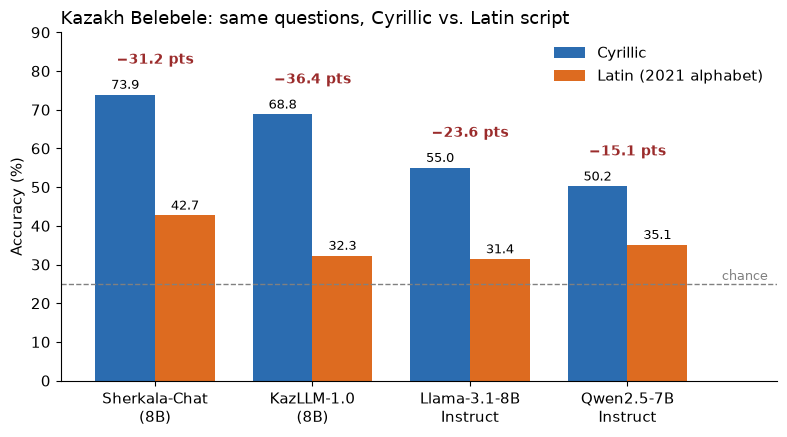

saved /content/drive/MyDrive/kazakh-latin-robustness/results/figures/accuracy.png


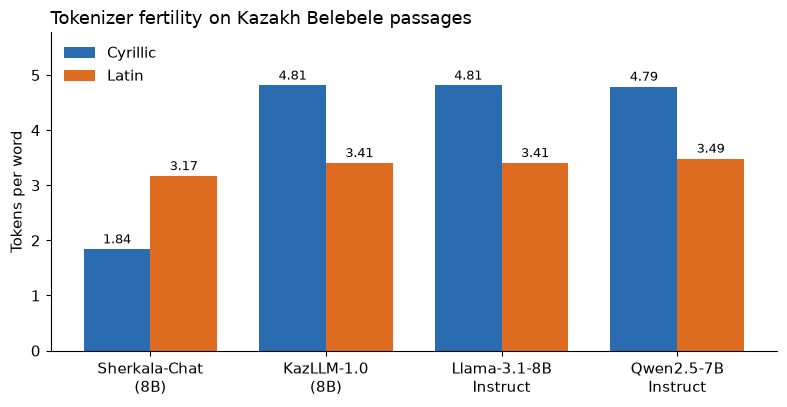

saved /content/drive/MyDrive/kazakh-latin-robustness/results/figures/fertility.png


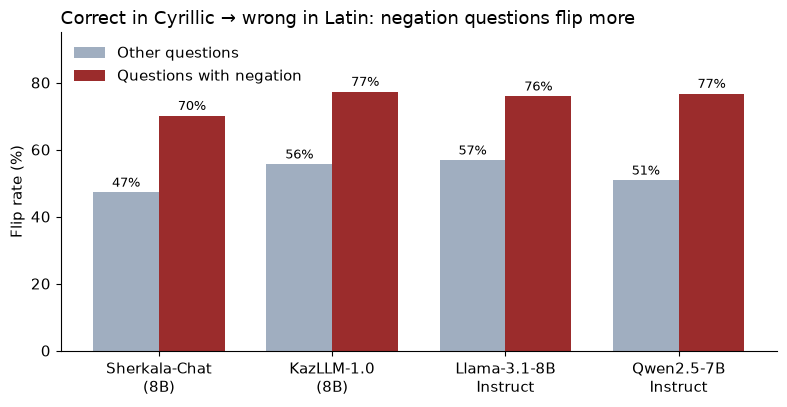

saved /content/drive/MyDrive/kazakh-latin-robustness/results/figures/negation_flips.png


In [23]:
# Standalone: also works in a fresh runtime (mounts Drive only if it isn't mounted yet).
import os, re, json
import numpy as np
import pandas as pd
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/kazakh-latin-robustness"
if "MODELS" not in globals():
    MODELS = ["sherkala", "kazllm", "qwen", "llama"]
import matplotlib.pyplot as plt

OUT = f"{ROOT}/results"
FIG = f"{OUT}/figures"
os.makedirs(FIG, exist_ok=True)

ORDER = ["sherkala", "kazllm", "llama", "qwen"]
LABEL = {"sherkala": "Sherkala-Chat\n(8B)", "kazllm": "KazLLM-1.0\n(8B)",
         "llama": "Llama-3.1-8B\nInstruct", "qwen": "Qwen2.5-7B\nInstruct"}
BLUE, ORANGE, GRAY, RED = "#2b6cb0", "#dd6b20", "#a0aec0", "#9b2c2c"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def grouped_bars(ax, tags, series, fmt):
    """series: [(values, color, legend label), (values, color, legend label)]"""
    x, w = np.arange(len(tags)), 0.38
    for off, (vals, color, label) in zip((-w / 2, w / 2), series):
        bars = ax.bar(x + off, vals, w, color=color, label=label)
        ax.bar_label(bars, labels=[fmt(v) for v in vals], padding=2, fontsize=9)
    ax.set_xticks(x, [LABEL[t] for t in tags])
    return x

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
    plt.show()
    print("saved", f"{FIG}/{name}")

def ordered(df):
    df = df.set_index("model")
    return [t for t in ORDER if t in df.index], df

# accuracy.png
if os.path.exists(f"{OUT}/main_table.csv"):
    tags, df = ordered(pd.read_csv(f"{OUT}/main_table.csv"))
    cyr, lat = df.loc[tags, "acc_cyrl"] * 100, df.loc[tags, "acc_latn"] * 100
    drop = df.loc[tags, "drop"] * 100          # from the table, not from rounded accuracies
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = grouped_bars(ax, tags, [(cyr, BLUE, "Cyrillic"), (lat, ORANGE, "Latin (2021 alphabet)")],
                     lambda v: f"{v:.1f}")
    for xi, c, dr in zip(x, cyr, drop):
        ax.text(xi, c + 8, f"−{dr:.1f} pts", ha="center", color=RED, fontweight="bold", fontsize=10)
    ax.axhline(25, ls="--", c="gray", lw=1)
    ax.set_xlim(-0.6, len(tags) - 1 + 0.95)
    ax.text(len(tags) - 1 + 0.6, 26, "chance", color="gray", fontsize=9, ha="left")
    ax.set_ylim(0, 90); ax.set_ylabel("Accuracy (%)")
    ax.set_title("Kazakh Belebele: same questions, Cyrillic vs. Latin script", loc="left")
    ax.legend(frameon=False, loc="upper right")
    save(fig, "accuracy.png")
else:
    print("main_table.csv not found -> run section 7 first")

# fertility.png
if os.path.exists(f"{OUT}/fertility.csv"):
    tags, df = ordered(pd.read_csv(f"{OUT}/fertility.csv"))
    fc, fl = df.loc[tags, "fertility_cyrl"], df.loc[tags, "fertility_latn"]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    grouped_bars(ax, tags, [(fc, BLUE, "Cyrillic"), (fl, ORANGE, "Latin")], lambda v: f"{v:.2f}")
    ax.set_ylim(0, max(fc.max(), fl.max()) * 1.2); ax.set_ylabel("Tokens per word")
    ax.set_title("Tokenizer fertility on Kazakh Belebele passages", loc="left")
    ax.legend(frameon=False, loc="upper left")
    save(fig, "fertility.png")
else:
    print("fertility.csv not found -> run section 5 first")

# negation_flips.png
if os.path.exists(f"{OUT}/feature_flip_rates.csv"):
    ff = pd.read_csv(f"{OUT}/feature_flip_rates.csv")
    tags, df = ordered(ff[ff["feature"] == "negation"])
    other, neg = df.loc[tags, "flip_rate_without"] * 100, df.loc[tags, "flip_rate_with"] * 100
    fig, ax = plt.subplots(figsize=(8, 4.2))
    grouped_bars(ax, tags, [(other, GRAY, "Other questions"), (neg, RED, "Questions with negation")],
                 lambda v: f"{v:.0f}%")
    ax.set_ylim(0, 95); ax.set_ylabel("Flip rate (%)")
    ax.set_title("Correct in Cyrillic → wrong in Latin: negation questions flip more", loc="left")
    ax.legend(frameon=False, loc="upper left")
    save(fig, "negation_flips.png")
else:
    print("feature_flip_rates.csv not found -> run section 9 first")

## Files needed for the report
- `translit/cyr2lat.py`, `data/belebele_kaz_*.jsonl`, `data/translit_gold_50.csv`
- `results/main_table.csv`, `results/fertility.csv`, `results/feature_flip_rates.csv`, `results/negation_difficulty_check.csv`, `results/iy_merger_flip_rates.csv`
- `results/preds_<model>_<script>.csv`, `results/errors_*.csv`
- `results/figures/accuracy.png`, `results/figures/fertility.png`, `results/figures/negation_flips.png`